<a href="https://colab.research.google.com/github/shriya-dev-ui/lab1aiml/blob/main/Stroke_SMOTE_Classifier_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Exercise: Handling Class Imbalance with SMOTE on the Stroke Dataset
**Course:** B.Tech CSE (AI & ML)

**Objective:** Balance the processed Stroke dataset using **SMOTE**, train six classifiers (Logistic Regression, KNN, Decision Tree, Random Forest, SVM, ANN), evaluate them (Precision, Recall, F1, Accuracy, AUC-ROC, Confusion Matrix), compare against the original imbalanced results and identify the **Top 3 models**.

**Workflow**
1. Upload the dataset and inspect the class imbalance
2. Preprocessing and stratified train/test split
3. Baseline: train six models on the **imbalanced** data
4. Apply **SMOTE** (on the training set only, to avoid data leakage)
5. Train six models on the **balanced** data
6. Confusion matrices and ROC curves
7. Comparison tables and Top 3 models

## 1. Install / Import Libraries

In [1]:
!pip install -q imbalanced-learn

import warnings, io
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, confusion_matrix, roc_curve)
from imblearn.over_sampling import SMOTE

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
sns.set_style("whitegrid")
print("Libraries loaded successfully")

Libraries loaded successfully


## 2. Upload the Dataset (manual entry)
Run the cell below and choose your **processed Stroke dataset** (CSV or Excel) from your computer.

In [2]:
from google.colab import files

uploaded = files.upload()
file_name = list(uploaded.keys())[0]
print("Uploaded:", file_name)

if file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(uploaded[file_name]))
else:
    df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Shape:", df.shape)
df.head()

Saving stroke_processed_5k.csv to stroke_processed_5k.csv
Uploaded: stroke_processed_5k.csv
Shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


### Configuration
Set the name of the target column below (default: `stroke`). If your column is named differently, change it here.

In [3]:
TARGET = "stroke"          # <-- change if your target column has a different name
TEST_SIZE = 0.2

# Case-insensitive match for convenience
match = [c for c in df.columns if c.lower() == TARGET.lower()]
assert match, f"Target column '{TARGET}' not found. Available columns: {list(df.columns)}"
TARGET = match[0]
print("Target column:", TARGET)

df.info()

Target column: stroke
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 439.3 KB


## 3. Explore Class Imbalance

stroke
0    4861
1     249
Name: count, dtype: int64

Percentage distribution:
 stroke
0    95.13
1     4.87
Name: count, dtype: float64

Imbalance ratio (majority : minority) = 19.52 : 1


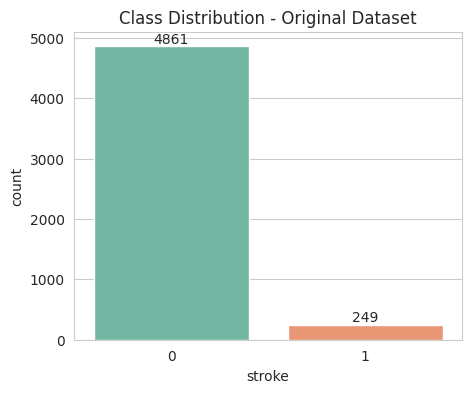

In [4]:
counts = df[TARGET].value_counts()
print(counts)
print("\nPercentage distribution:\n", (counts / len(df) * 100).round(2))
print(f"\nImbalance ratio (majority : minority) = {counts.max() / counts.min():.2f} : 1")

plt.figure(figsize=(5, 4))
ax = sns.countplot(x=TARGET, data=df, palette="Set2")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Class Distribution - Original Dataset")
plt.show()

## 4. Preprocessing
The dataset is described as *processed*, but this cell safely handles anything left over: drops ID columns, fills missing values, and one-hot encodes any remaining text columns.

In [5]:
data = df.copy()

# Drop identifier columns if present
for c in data.columns:
    if c.lower() in ("id", "unnamed: 0", "index"):
        data.drop(columns=c, inplace=True)

# Encode target if it is non-numeric
if data[TARGET].dtype == "object":
    data[TARGET] = data[TARGET].astype("category").cat.codes

# Handle missing values
for c in data.columns.drop(TARGET):
    if data[c].isnull().any():
        if data[c].dtype == "object":
            data[c].fillna(data[c].mode()[0], inplace=True)
        else:
            data[c].fillna(data[c].median(), inplace=True)
data.dropna(subset=[TARGET], inplace=True)

# One-hot encode remaining categorical columns
cat_cols = data.drop(columns=TARGET).select_dtypes(include="object").columns.tolist()
if cat_cols:
    print("Encoding categorical columns:", cat_cols)
    data = pd.get_dummies(data, columns=cat_cols, drop_first=True)

X = data.drop(columns=TARGET).astype(float)
y = data[TARGET].astype(int)
print("Features:", X.shape[1], "| Samples:", X.shape[0])

Features: 10 | Samples: 5110


In [6]:
# Stratified split keeps the same class ratio in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

# Scale features (fit on train only)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print("Train class counts:", dict(pd.Series(y_train).value_counts()))
print("Test  class counts:", dict(pd.Series(y_test).value_counts()))

Train class counts: {0: np.int64(3889), 1: np.int64(199)}
Test  class counts: {0: np.int64(972), 1: np.int64(50)}


## 5. Model Definitions and Evaluation Helpers
Six models are used: **Logistic Regression, KNN, Decision Tree, Random Forest, SVM** (5 ML classifiers) and an **ANN** (Keras).
Metrics are computed for the positive class (**stroke = 1**).

In [7]:
def get_ml_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        "SVM": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    }

def build_ann(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return model

def compute_metrics(y_true, y_pred, y_prob):
    return {
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC-ROC": roc_auc_score(y_true, y_prob),
    }

def run_all_models(X_tr, y_tr, X_te, y_te):
    """Trains all 6 models; returns metrics DataFrame, predictions, probabilities."""
    results, preds, probs = {}, {}, {}

    for name, model in get_ml_models().items():
        model.fit(X_tr, y_tr)
        prob = model.predict_proba(X_te)[:, 1]
        pred = (prob >= 0.5).astype(int)
        results[name], preds[name], probs[name] = compute_metrics(y_te, pred, prob), pred, prob

    ann = build_ann(X_tr.shape[1])
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    ann.fit(X_tr, np.asarray(y_tr), epochs=100, batch_size=32, validation_split=0.2,
            callbacks=[es], verbose=0)
    prob = ann.predict(X_te, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    results["ANN"], preds["ANN"], probs["ANN"] = compute_metrics(y_te, pred, prob), pred, prob

    return pd.DataFrame(results).T.round(4), preds, probs

def plot_confusion_matrices(preds, y_te, title):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, (name, pred) in zip(axes.ravel(), preds.items()):
        cm = confusion_matrix(y_te, pred)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=["No Stroke", "Stroke"], yticklabels=["No Stroke", "Stroke"])
        ax.set_title(name)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
    fig.suptitle(title, fontsize=15, y=1.02)
    plt.tight_layout()
    plt.show()

def plot_roc(probs, y_te, title):
    plt.figure(figsize=(7, 6))
    for name, prob in probs.items():
        fpr, tpr, _ = roc_curve(y_te, prob)
        plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_te, prob):.3f})")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.show()

## 6. Baseline: Models on the ORIGINAL (Imbalanced) Data

In [8]:
res_imb, preds_imb, probs_imb = run_all_models(X_train_sc, y_train, X_test_sc, y_test)
print("Results on ORIGINAL imbalanced data")
res_imb

Results on ORIGINAL imbalanced data


,Precision,Recall,F1-Score,Accuracy,AUC-ROC
Logistic Regression,0.0000,0.00,0.0000,0.9511,0.8377
KNN,0.2000,0.02,0.0364,0.9481,0.6140
Decision Tree,0.1667,0.18,0.1731,0.9159,0.5669
Random Forest,0.0000,0.00,0.0000,0.9481,0.8083
SVM,0.0000,0.00,0.0000,0.9511,0.6108
ANN,0.0000,0.00,0.0000,0.9511,0.8247


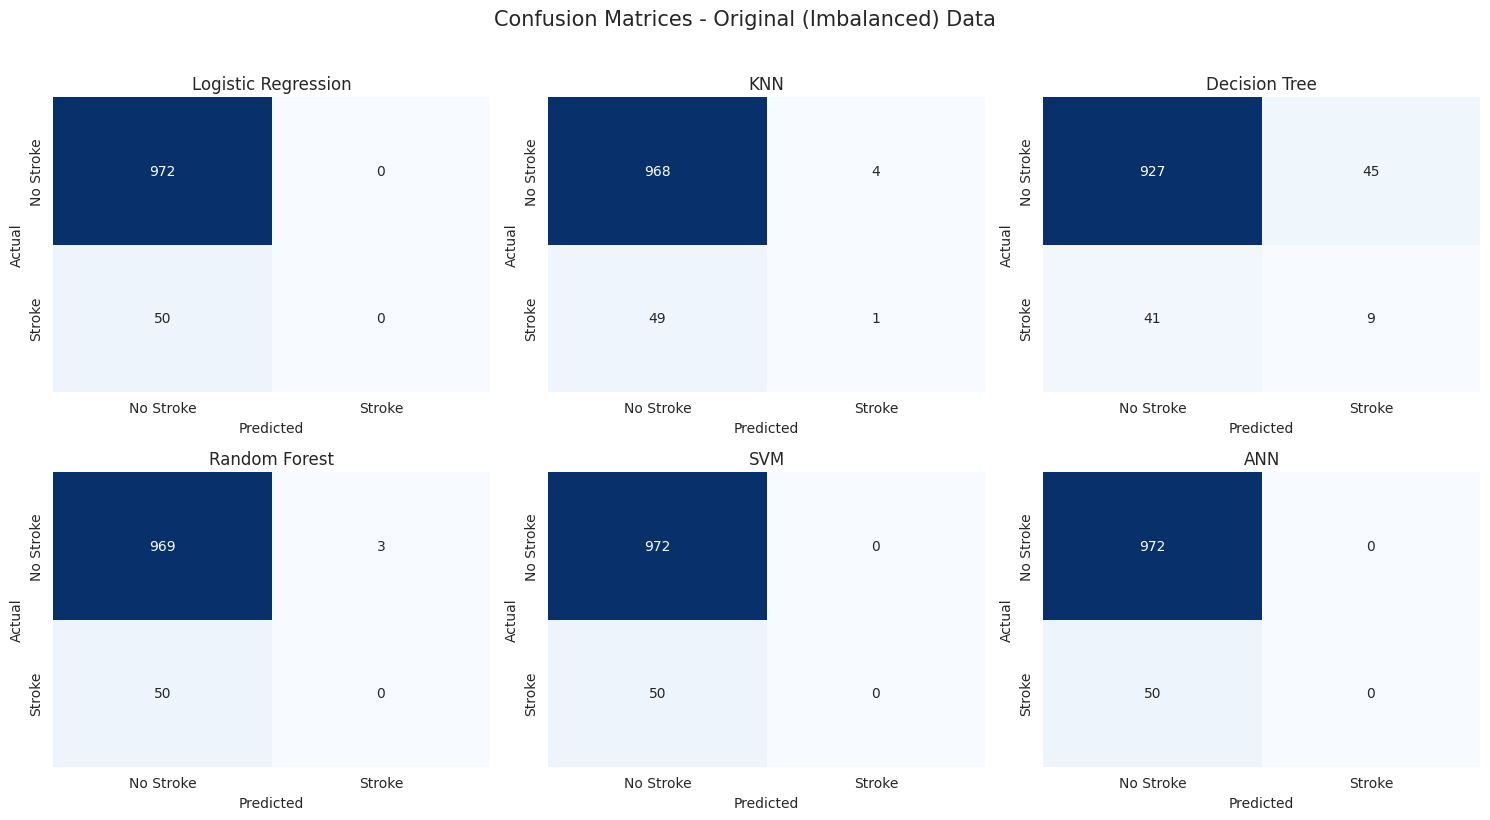

In [9]:
plot_confusion_matrices(preds_imb, y_test, "Confusion Matrices - Original (Imbalanced) Data")

## 7. Apply SMOTE
SMOTE creates synthetic minority-class samples by interpolating between a minority sample and its nearest minority neighbours.
It is applied **only to the training set**; the test set stays untouched so that evaluation reflects real-world data.

Before SMOTE: {0: np.int64(3889), 1: np.int64(199)}
After  SMOTE: {0: np.int64(3889), 1: np.int64(3889)}


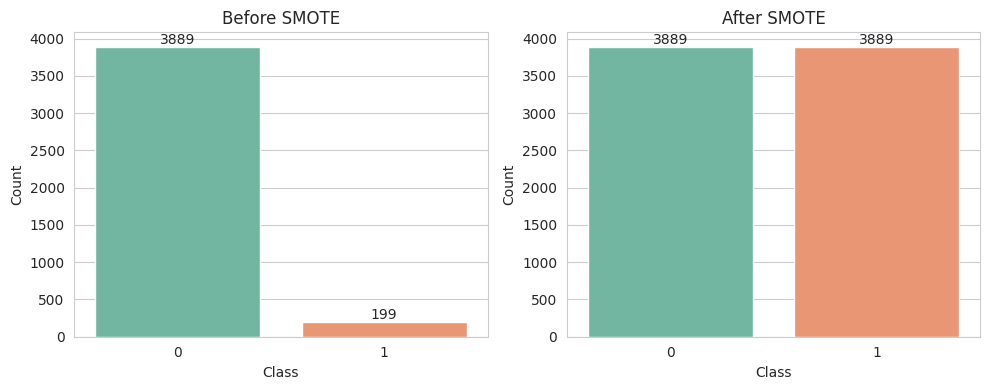

In [10]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train_sc, y_train)

print("Before SMOTE:", dict(pd.Series(y_train).value_counts()))
print("After  SMOTE:", dict(pd.Series(y_train_sm).value_counts()))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, yy, t in zip(axes, [y_train, y_train_sm], ["Before SMOTE", "After SMOTE"]):
    vc = pd.Series(yy).value_counts().sort_index()
    sns.barplot(x=vc.index, y=vc.values, palette="Set2", ax=ax)
    for i, v in enumerate(vc.values):
        ax.text(i, v, str(v), ha="center", va="bottom")
    ax.set_title(t)
    ax.set_xlabel("Class")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

## 8. Models on the SMOTE-BALANCED Data

In [11]:
res_sm, preds_sm, probs_sm = run_all_models(X_train_sm, y_train_sm, X_test_sc, y_test)
print("Results on SMOTE-balanced data")
res_sm

Results on SMOTE-balanced data


,Precision,Recall,F1-Score,Accuracy,AUC-ROC
Logistic Regression,0.1460,0.80,0.2469,0.7613,0.8381
KNN,0.0884,0.32,0.1385,0.8053,0.6639
Decision Tree,0.1184,0.18,0.1429,0.8943,0.5555
Random Forest,0.1579,0.12,0.1364,0.9256,0.7864
SVM,0.1359,0.56,0.2188,0.8043,0.7762
ANN,0.1407,0.38,0.2054,0.8562,0.7826


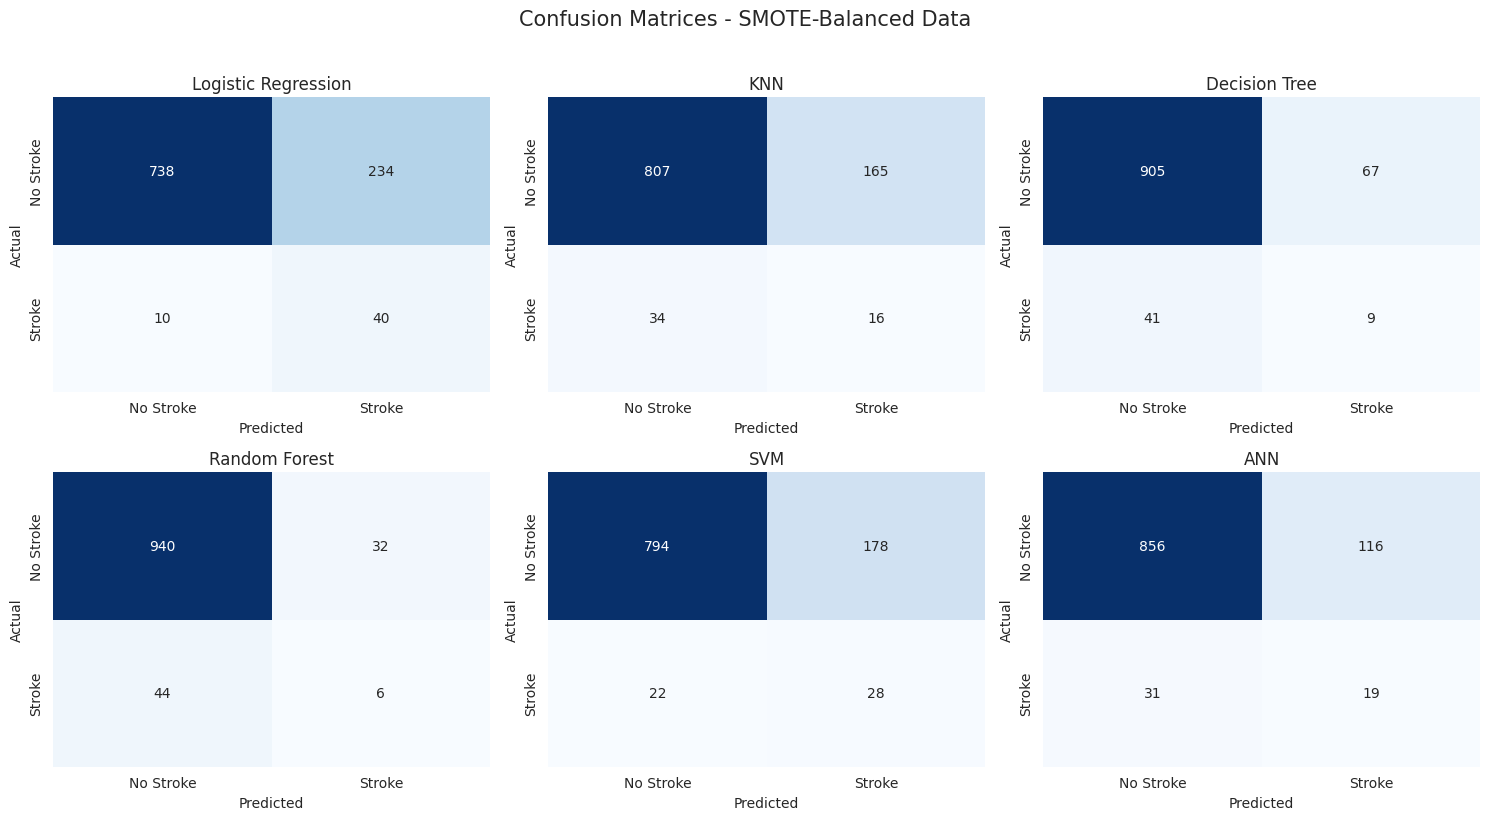

In [12]:
plot_confusion_matrices(preds_sm, y_test, "Confusion Matrices - SMOTE-Balanced Data")

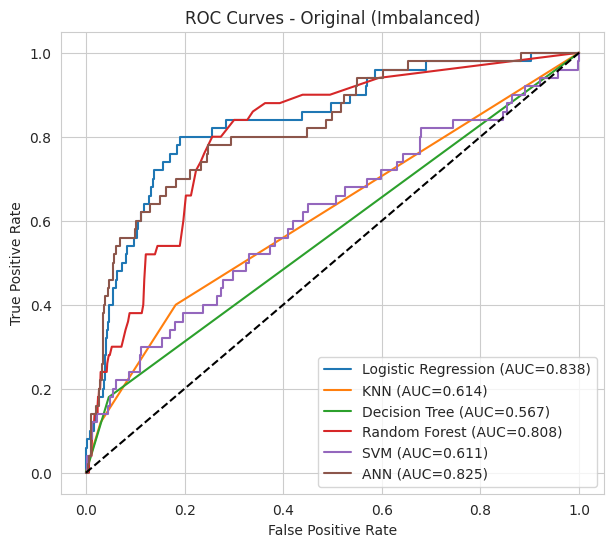

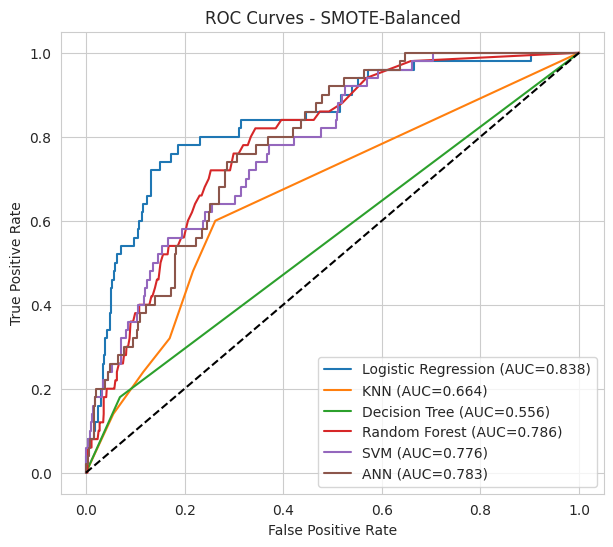

In [13]:
fig_titles = [("Original (Imbalanced)", probs_imb), ("SMOTE-Balanced", probs_sm)]
for t, p in fig_titles:
    plot_roc(p, y_test, f"ROC Curves - {t}")

## 9. Comparative Results: Imbalanced vs SMOTE

In [14]:
comparison = pd.concat({"Imbalanced (Original)": res_imb, "SMOTE (Balanced)": res_sm}, axis=1)
comparison = comparison.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
display(comparison)

AUC-ROC                   \
                    Imbalanced (Original) SMOTE (Balanced)   
Logistic Regression                0.8377           0.8381   
KNN                                0.6140           0.6639   
Decision Tree                      0.5669           0.5555   
Random Forest                      0.8083           0.7864   
SVM                                0.6108           0.7762   
ANN                                0.8247           0.7826   

                                 Accuracy                   \
                    Imbalanced (Original) SMOTE (Balanced)   
Logistic Regression                0.9511           0.7613   
KNN                                0.9481           0.8053   
Decision Tree                      0.9159           0.8943   
Random Forest                      0.9481           0.9256   
SVM                                0.9511           0.8043   
ANN                                0.9511           0.8562   

                                 F1-Score                   \
                    Imbalanced (Original) SMOTE (Balanced)   
Logistic Regression                0.0000           0.2469   
KNN                                0.0364           0.1385   
Decision Tree                      0.1731           0.1429   
Random Forest                      0.0000           0.1364   
SVM                                0.0000           0.2188   
ANN                                0.0000           0.2054   

                                Precision                   \
                    Imbalanced (Original) SMOTE (Balanced)   
Logistic Regression                0.0000           0.1460   
KNN                                0.2000           0.0884   
Decision Tree                      0.1667           0.1184   
Random Forest                      0.0000           0.1579   
SVM                                0.0000           0.1359   
ANN                                0.0000           0.1407   

                                   Recall                   
                    Imbalanced (Original) SMOTE (Balanced)  
Logistic Regression                  0.00             0.80  
KNN                                  0.02             0.32  
Decision Tree                        0.18             0.18  
Random Forest                        0.00             0.12  
SVM                                  0.00             0.56  
ANN                                  0.00             0.38

In [15]:
# Change in each metric after SMOTE (SMOTE - Original)
delta = (res_sm - res_imb).round(4)
delta.columns = [f"Δ {c}" for c in delta.columns]
print("Change in performance after applying SMOTE")
display(delta.style.background_gradient(cmap="RdYlGn", axis=None))

Change in performance after applying SMOTE


,Δ Precision,Δ Recall,Δ F1-Score,Δ Accuracy,Δ AUC-ROC
Logistic Regression,0.146000,0.800000,0.246900,-0.189800,0.000400
KNN,-0.111600,0.300000,0.102100,-0.142800,0.049900
Decision Tree,-0.048300,0.000000,-0.030200,-0.021600,-0.011400
Random Forest,0.157900,0.120000,0.136400,-0.022500,-0.021900
SVM,0.135900,0.560000,0.218800,-0.146800,0.165400
ANN,0.140700,0.380000,0.205400,-0.094900,-0.042100


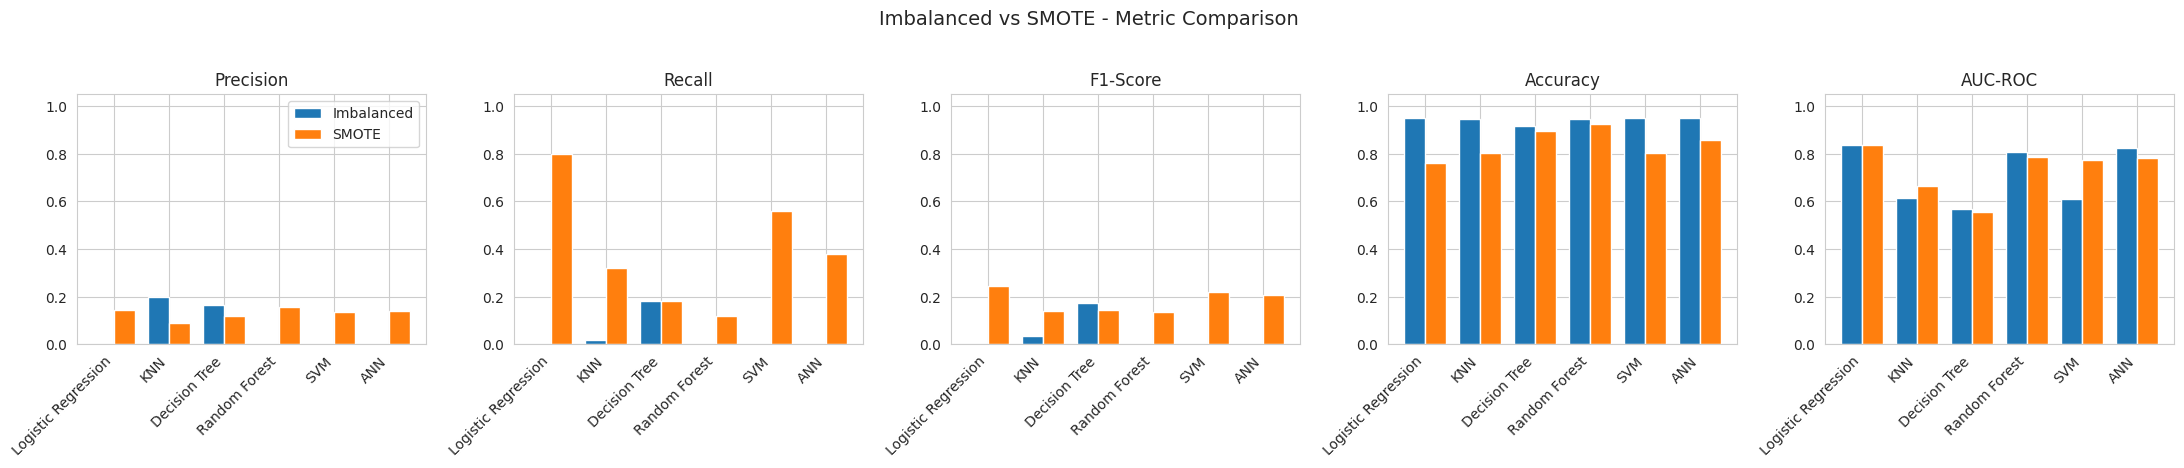

In [16]:
metrics = ["Precision", "Recall", "F1-Score", "Accuracy", "AUC-ROC"]
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharey=False)
x = np.arange(len(res_imb))
w = 0.38
for ax, m in zip(axes, metrics):
    ax.bar(x - w/2, res_imb[m], w, label="Imbalanced")
    ax.bar(x + w/2, res_sm[m], w, label="SMOTE")
    ax.set_xticks(x)
    ax.set_xticklabels(res_imb.index, rotation=45, ha="right")
    ax.set_title(m)
    ax.set_ylim(0, 1.05)
axes[0].legend()
plt.suptitle("Imbalanced vs SMOTE - Metric Comparison", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

## 10. Top 3 Models for Stroke Prediction (SMOTE-Balanced Data)
On medical data with rare positives, **Accuracy is misleading**, since a model that predicts "No Stroke" for everyone still scores high.
Models are therefore ranked by a composite score focused on the minority class:

**Composite Score = mean(Recall, F1-Score, AUC-ROC)**

Recall is included because missing a real stroke case (false negative) is the costly error.

In [17]:
final = res_sm.copy()
final["Composite Score"] = final[["Recall", "F1-Score", "AUC-ROC"]].mean(axis=1).round(4)
final = final.sort_values("Composite Score", ascending=False)
final.insert(0, "Rank", range(1, len(final) + 1))

print("Final Ranking of Models (SMOTE-Balanced Data)")
display(final.style.background_gradient(cmap="Greens", subset=["Composite Score"]))

top3 = final.head(3)
print("\nTOP 3 MODELS FOR STROKE PREDICTION")
display(top3)

Final Ranking of Models (SMOTE-Balanced Data)


,Rank,Precision,Recall,F1-Score,Accuracy,AUC-ROC,Composite Score
Logistic Regression,1,0.146000,0.800000,0.246900,0.761300,0.838100,0.628300
SVM,2,0.135900,0.560000,0.218800,0.804300,0.776200,0.518300
ANN,3,0.140700,0.380000,0.205400,0.856200,0.782600,0.456000
KNN,4,0.088400,0.320000,0.138500,0.805300,0.663900,0.374100
Random Forest,5,0.157900,0.120000,0.136400,0.925600,0.786400,0.347600
Decision Tree,6,0.118400,0.180000,0.142900,0.894300,0.555500,0.292800



TOP 3 MODELS FOR STROKE PREDICTION


,Rank,Precision,Recall,F1-Score,Accuracy,AUC-ROC,Composite Score
Logistic Regression,1,0.1460,0.80,0.2469,0.7613,0.8381,0.6283
SVM,2,0.1359,0.56,0.2188,0.8043,0.7762,0.5183
ANN,3,0.1407,0.38,0.2054,0.8562,0.7826,0.4560


## 11. Final Structured Summary Table

In [18]:
summary = pd.DataFrame({
    "Model": res_imb.index,
    "Imb. Precision": res_imb["Precision"].values,
    "Imb. Recall": res_imb["Recall"].values,
    "Imb. F1": res_imb["F1-Score"].values,
    "Imb. Accuracy": res_imb["Accuracy"].values,
    "Imb. AUC": res_imb["AUC-ROC"].values,
    "SMOTE Precision": res_sm["Precision"].values,
    "SMOTE Recall": res_sm["Recall"].values,
    "SMOTE F1": res_sm["F1-Score"].values,
    "SMOTE Accuracy": res_sm["Accuracy"].values,
    "SMOTE AUC": res_sm["AUC-ROC"].values,
}).set_index("Model")
summary["SMOTE Rank"] = final["Rank"].reindex(summary.index)
display(summary.sort_values("SMOTE Rank"))

summary.to_csv("stroke_smote_comparison.csv")
print("Saved: stroke_smote_comparison.csv")
# files.download("stroke_smote_comparison.csv")   # uncomment to download

,Imb. Precision,Imb. Recall,Imb. F1,Imb. Accuracy,Imb. AUC,SMOTE Precision,SMOTE Recall,SMOTE F1,SMOTE Accuracy,SMOTE AUC,SMOTE Rank
Model,,,,,,,,,,,
Logistic Regression,0.0000,0.00,0.0000,0.9511,0.8377,0.1460,0.80,0.2469,0.7613,0.8381,1
SVM,0.0000,0.00,0.0000,0.9511,0.6108,0.1359,0.56,0.2188,0.8043,0.7762,2
ANN,0.0000,0.00,0.0000,0.9511,0.8247,0.1407,0.38,0.2054,0.8562,0.7826,3
KNN,0.2000,0.02,0.0364,0.9481,0.6140,0.0884,0.32,0.1385,0.8053,0.6639,4
Random Forest,0.0000,0.00,0.0000,0.9481,0.8083,0.1579,0.12,0.1364,0.9256,0.7864,5
Decision Tree,0.1667,0.18,0.1731,0.9159,0.5669,0.1184,0.18,0.1429,0.8943,0.5555,6


Saved: stroke_smote_comparison.csv


## 12. Observations / Conclusion
Fill in after running the notebook with your data:

- **Effect of imbalance:** On the original data, models show high accuracy but very low Recall/F1 for the stroke class, since they are biased towards the majority class.
- **Effect of SMOTE:** After balancing, Recall (and usually F1) of the minority class improves, at the cost of some Precision and Accuracy, because more false positives appear.
- **Best models:** The Top 3 models are listed in Section 10.
- **Caution:** SMOTE was applied only on the training set, and the test set preserves the real class distribution, so the reported results are not inflated by synthetic samples.
- **Metric choice:** For stroke screening, a high Recall is preferred, as a missed stroke case is costlier than a false alarm.